In [1]:
!pip install avalanche-lib

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

In [3]:
import pandas as pd

from benchmarks.benchmark_factory import build_benchmark
from models.model_factory import build_model
from evaluation.evaluator_factory import build_evaluator
from strategies.strategy_factory import build_strategy
from experiments.runner import run_continual_experiment, run_joint_experiment
from evaluation.plots import *

In [4]:
benchmark_name = "split_mnist"
model_name = "avalanche_simplemlp"
n_experiences = 5
num_classes = 10

seed = 124

EXPERIMENTS = [
    {
        "name": "joint",
        "strategy_name": "joint",
        "plugin_names": [],
        "lr": 0.01,
        "train_epochs": 5,
    },
    {
        "name": "naive",
        "strategy_name": "naive",
        "plugin_names": [],
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "ewc",
        "strategy_name": "naive",
        "plugin_names": ["ewc"],
        "ewc_lambda": 0.4,
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "replay",
        "strategy_name": "naive",
        "plugin_names": ["replay"],
        "mem_size": 500,
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "ewc_replay",
        "strategy_name": "naive",
        "plugin_names": ["ewc", "replay"],
        "ewc_lambda": 0.4,
        "mem_size": 500,
        "lr": 0.01,
        "train_epochs": 1,
    },
]

all_results = {}

for config in EXPERIMENTS:
    approach_name = config["name"]
    strategy_name = config["strategy_name"]

    output_dir = f"../outputs/{benchmark_name}/{approach_name}/{model_name}/"

    print("\n" + "=" * 80)
    print(f"Running: {approach_name}")
    print("=" * 80)

    benchmark = build_benchmark(
        benchmark_name=benchmark_name,
        n_experiences=n_experiences,
        seed=seed,
    )

    model = build_model(
        model_name=model_name,
        num_classes=num_classes,
    )

    evaluator = build_evaluator(
        log_dir=output_dir + "logs",
        use_interactive=False,
        use_text=False,
        use_tensorboard=True,
    )

    strategy_kwargs = {
        k: v for k, v in config.items()
        if k not in [
            "name",
            "strategy_name",
            "plugin_names",
            "lr",
            "train_epochs",
        ]
    }

    strategy = build_strategy(
        strategy_name=strategy_name,
        model=model,
        evaluator=evaluator,
        optimizer_name="sgd",
        lr=config["lr"],
        momentum=0.9,
        train_mb_size=64,
        eval_mb_size=128,
        train_epochs=config["train_epochs"],
        plugin_names=config.get("plugin_names"),
        **strategy_kwargs,
    )

    if strategy_name == "joint":
        result = run_joint_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            save_outputs=False,
        )
    else:
        result = run_continual_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            save_outputs=False,
        )

    all_results[approach_name] = result


Running: joint


/opt/conda/lib/python3.10/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


Training JointTraining on full train stream
Evaluating JointTraining on full test stream

Running: naive
Training experience 0
Evaluating on full test stream for R matrix
Training experience 1
Evaluating on full test stream for R matrix
Training experience 2
Evaluating on full test stream for R matrix
Training experience 3
Evaluating on full test stream for R matrix
Training experience 4
Evaluating on full test stream for R matrix

Running: ewc
Training experience 0
Evaluating on full test stream for R matrix
Training experience 1
Evaluating on full test stream for R matrix
Training experience 2
Evaluating on full test stream for R matrix
Training experience 3
Evaluating on full test stream for R matrix
Training experience 4
Evaluating on full test stream for R matrix

Running: replay
Training experience 0


/opt/conda/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream for R matrix
Training experience 1


...

Evaluating on full test stream for R matrix
Training experience 3


/opt/conda/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream for R matrix
Training experience 4


/opt/conda/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream for R matrix


In [5]:
rows = []

for name, result in all_results.items():
    row = {"Strategy": name}
    row.update(result["metrics"])
    rows.append(row)

df = pd.DataFrame(rows)
df = df.round(4)
df = df.sort_values(by="A Metric", ascending=False)
display(df)

,Strategy,A Metric,ACC Metric,Model Size,BWT (Backward Transfer),BWT+ (Positive Backward Transfer),FWT (Forward Transfer),Forgetting,REM (Remembering),MS (Memory Score),SSS (Sample Storage Score),CE (Compute Efficiency),Total Train Time,Average Train Time,Estimated Baseline Ops,Estimated Total Ops
0,joint,0.9789,NaN,407050,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,54.1033,54.1033,NaN,NaN
3,replay,0.9104,0.9396,407050,-0.0648,0.0,0.0,0.0648,0.9352,1.0,1.0,1.0,17.5333,3.5067,2.442300e+10,2.442300e+10
4,ewc_replay,0.8934,0.9307,407050,-0.0781,0.0,0.0,0.0781,0.9219,1.0,1.0,1.0,29.4694,5.8939,2.442300e+10,2.442300e+10
1,naive,0.1964,0.3303,407050,-0.9937,0.0,0.0,0.9937,0.0063,1.0,1.0,1.0,10.9809,2.1962,2.442300e+10,2.442300e+10
2,ewc,0.1956,0.3299,407050,-0.9935,0.0,0.0,0.9935,0.0065,1.0,1.0,1.0,22.6858,4.5372,2.442300e+10,2.442300e+10


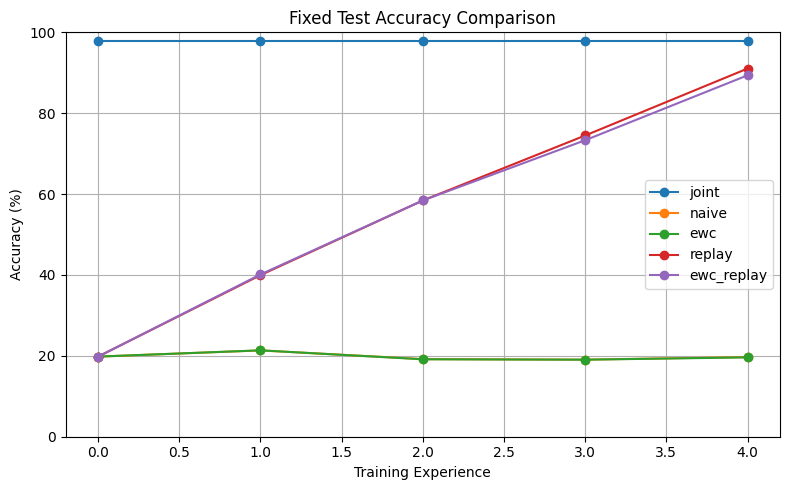

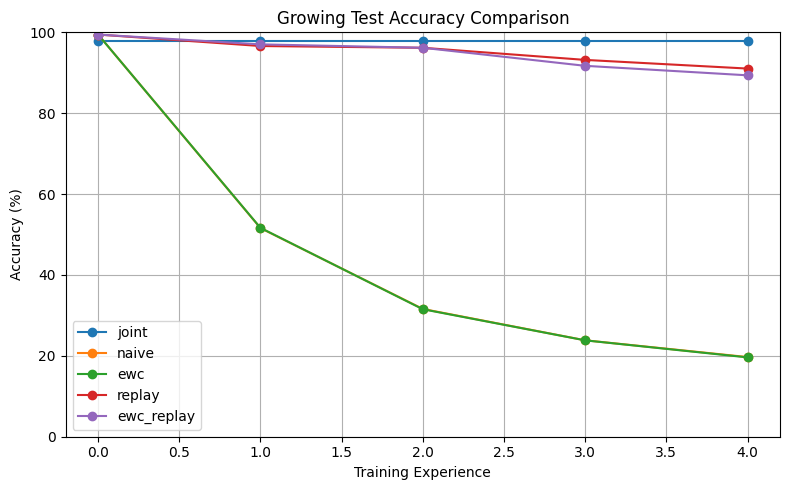

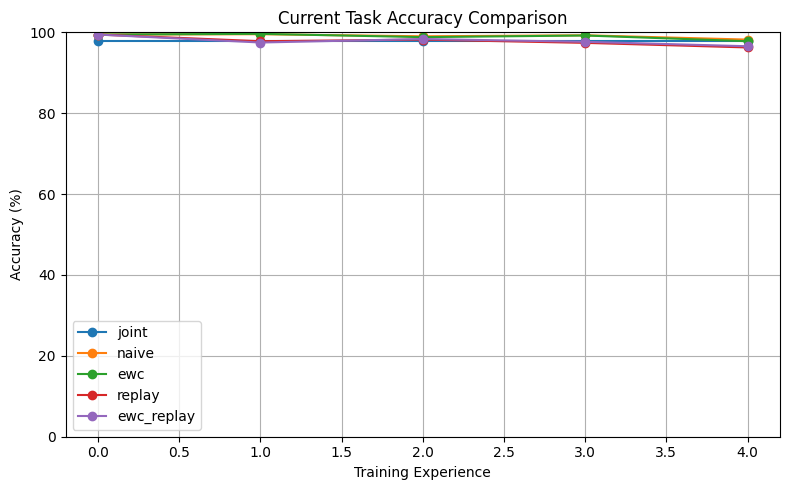

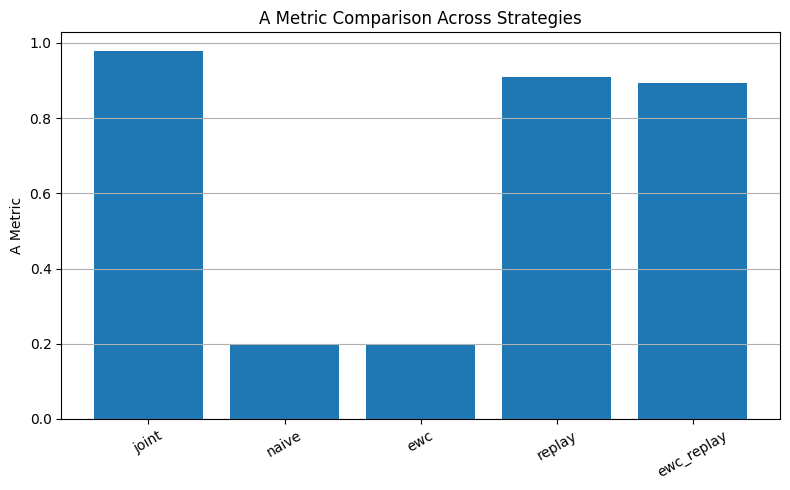

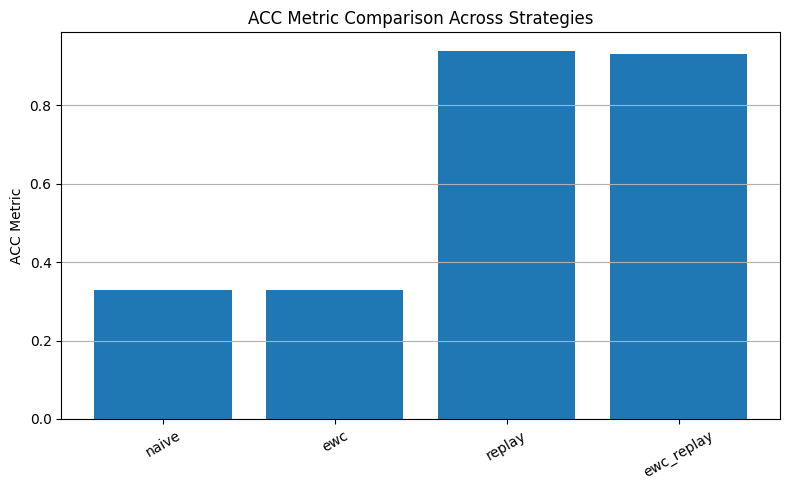

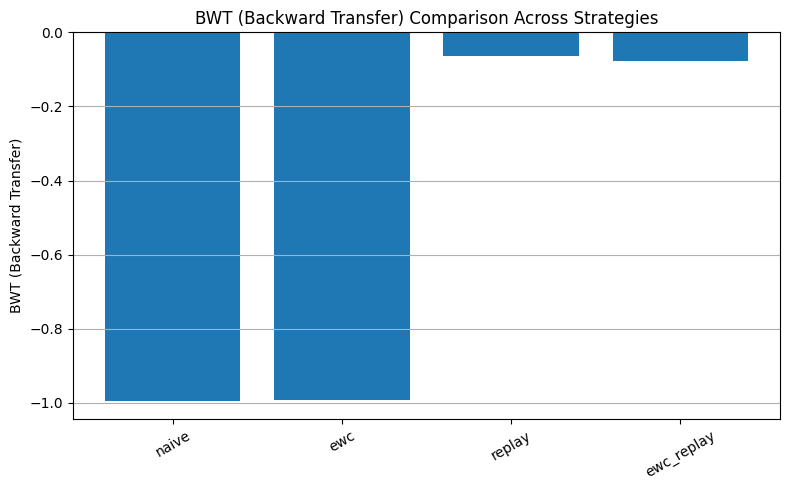

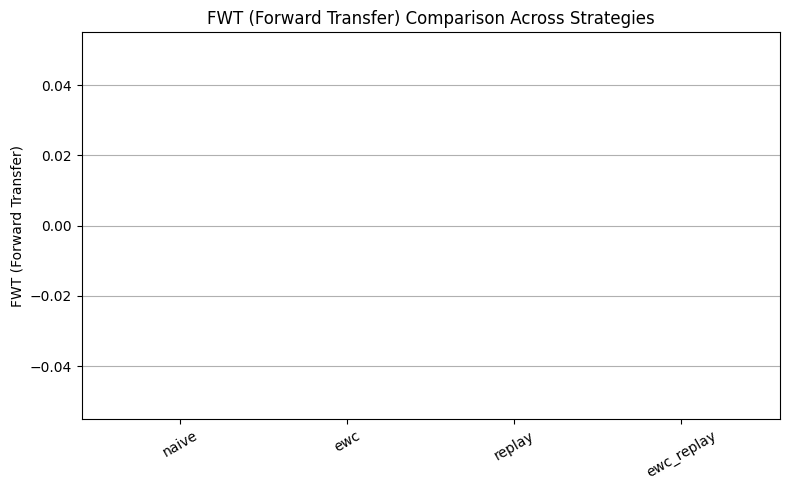

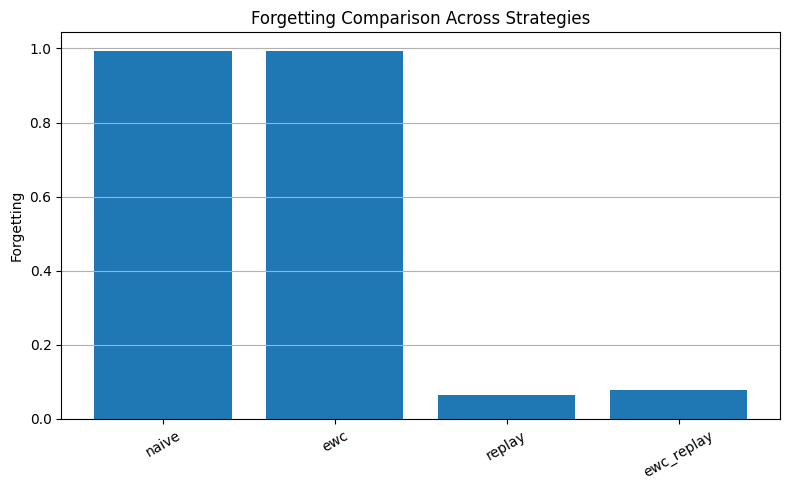

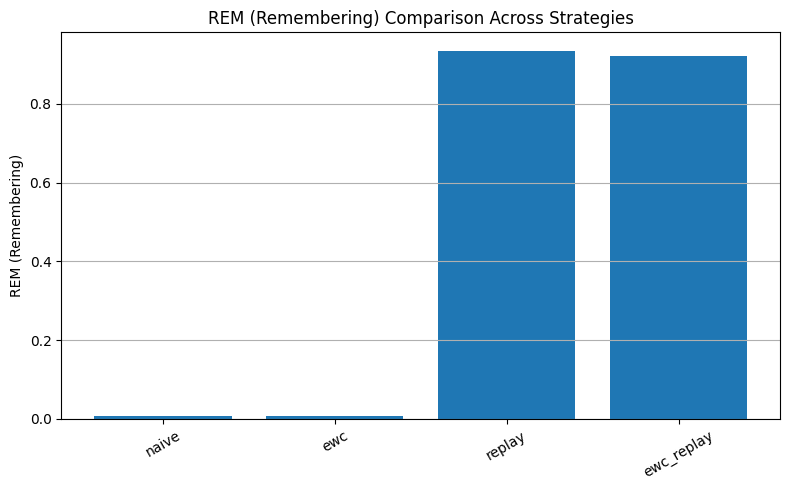

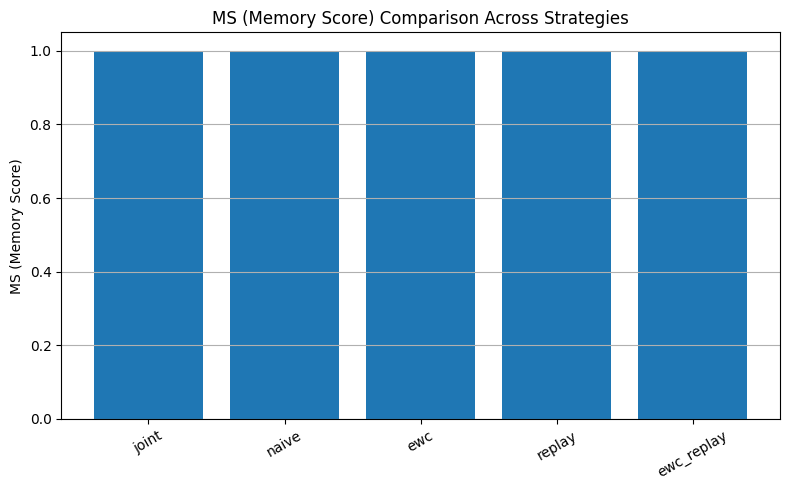

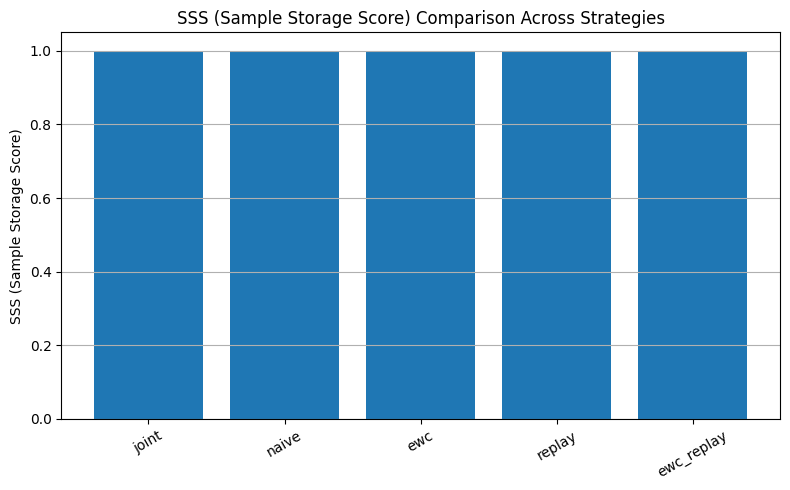

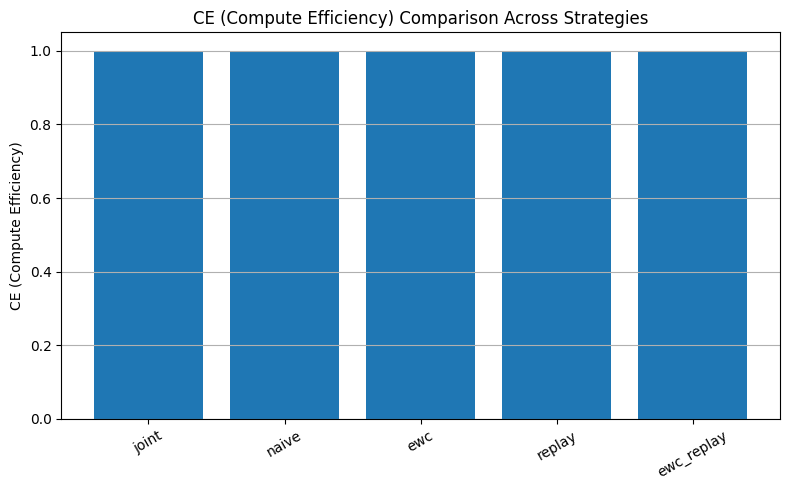

In [6]:
plot_fixed_comparison(all_results)
plot_growing_comparison(all_results)
plot_task_comparison(all_results)

for metric in [
    "A Metric",
    "ACC Metric",
    "BWT (Backward Transfer)",
    "FWT (Forward Transfer)",
    "Forgetting",
    "REM (Remembering)",
    "MS (Memory Score)",
    "SSS (Sample Storage Score)",
    "CE (Compute Efficiency)",
]:
    plot_metric_comparison(all_results, metric)